# MicroGrad — Scalar Autograd Engine: Demo Notebook
**CSE485–CSE488 Deep Learning · Assignment 1 · Ain Shams University**

## 1. Introduction
This notebook demonstrates the scalar automatic-differentiation engine implemented in `src/engine.py`
(the `Value` class) and the neural-network API built on top of it in `src/nn.py` (`Neuron`, `Layer`, `MLP`).

Every number in a computation is wrapped in a `Value`. Each operation records its inputs and a small
`_backward` closure holding the *local* derivative. Calling `backward()` on the final output topologically
sorts the graph and applies the chain rule from the output back to every input.

No PyTorch / TensorFlow / JAX is used anywhere. NumPy, scikit-learn and Matplotlib are used **only** to
generate the dataset and draw plots; all model computations and gradients come from our `Value` engine.

In [1]:
import os, sys, math, random, time

# Make the repository root importable regardless of where the notebook is launched from.
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

from src.engine import Value
from src.nn import Neuron, Layer, MLP

SEED = 42
random.seed(SEED)       # controls weight initialisation in src/nn.py
np.random.seed(SEED)

FIG_DIR = os.path.join(ROOT, 'report', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('Python', sys.version.split()[0])

Python 3.11.9


## 2. Scalar Values
A `Value` stores the scalar `data`, its gradient `grad` (initially 0), the set of parent nodes `_prev`,
the operation label `_op`, and an optional human-readable `label`.

In [2]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
print(a, b)
print('a.data =', a.data, '| a.grad =', a.grad, '| a._prev =', a._prev, '| a._op =', repr(a._op))

Value(data=2.0) Value(data=-3.0)
a.data = 2.0 | a.grad = 0.0 | a._prev = set() | a._op = ''


## 3. Mathematical Operations
Operator overloading builds the graph. Plain Python numbers are wrapped automatically, so `2 * a`
and `a + 1` work; unsupported types (strings, lists) raise `TypeError`.

In [3]:
x = Value(0.5)
ops = {
    'x + 2'    : x + 2,
    '3 * x'    : 3 * x,
    'x - 1'    : x - 1,
    'x / 4'    : x / 4,
    'x ** 3'   : x ** 3,
    '-x'       : -x,
    'x.exp()'  : x.exp(),
    'x.tanh()' : x.tanh(),
}
for name, v in ops.items():
    print(f'{name:10s} = {v.data: .6f}   (op: {v._op})')

try:
    Value(1.0) + 'string'
except TypeError as e:
    print('TypeError as expected:', e)

x + 2      =  2.500000   (op: +)
3 * x      =  1.500000   (op: *)
x - 1      = -0.500000   (op: +)
x / 4      =  0.125000   (op: *)
x ** 3     =  0.125000   (op: **3)
-x         = -0.500000   (op: *)
x.exp()    =  1.648721   (op: exp)
x.tanh()   =  0.462117   (op: tanh)
TypeError as expected: unsupported operand type(s) for +: 'Value' and 'str'


## 4. The Computational Graph
We build $L = (a\cdot b + c)\cdot f$ and print the nodes in the topological order returned by
`_get_topo()`. Each node appears only **after** all of its inputs (post-order DFS).

In [4]:
a = Value(2.0, label='a'); b = Value(-3.0, label='b'); c = Value(10.0, label='c'); f = Value(-2.0, label='f')
e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
L = d * f;  L.label = 'L'

for node in L._get_topo():
    inputs = ', '.join(sorted(p.label for p in node._prev)) or '-'
    print(f"{node.label:2s} data={node.data:6.1f}   op={node._op or 'leaf':4s}   inputs: {inputs}")

b  data=  -3.0   op=leaf   inputs: -
a  data=   2.0   op=leaf   inputs: -
e  data=  -6.0   op=*      inputs: a, b
c  data=  10.0   op=leaf   inputs: -
d  data=   4.0   op=+      inputs: c, e
f  data=  -2.0   op=leaf   inputs: -
L  data=  -8.0   op=*      inputs: d, f


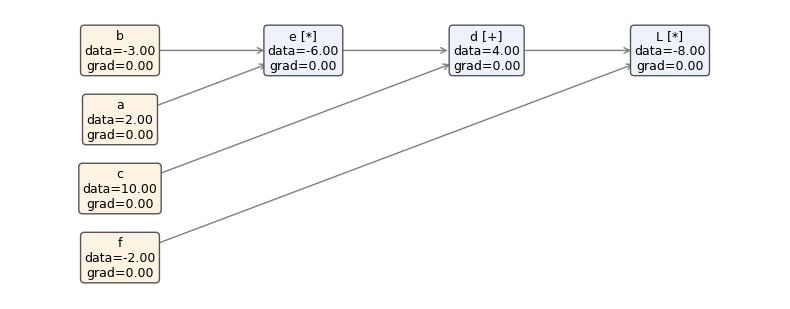

In [5]:
def draw_graph(root, fname=None):
    # Simple Matplotlib drawing of the graph: x-position = depth from the leaves.
    topo = root._get_topo()
    depth = {}
    for n in topo:
        depth[n] = 0 if not n._prev else 1 + max(depth[p] for p in n._prev)
    levels = {}
    for n in topo:
        levels.setdefault(depth[n], []).append(n)
    pos = {n: (d, -i) for d, ns in levels.items() for i, n in enumerate(ns)}
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for n in topo:
        for p in n._prev:
            ax.annotate('', xy=pos[n], xytext=pos[p],
                        arrowprops=dict(arrowstyle='->', color='gray', shrinkA=28, shrinkB=28))
    for n, (px, py) in pos.items():
        txt = f"{n.label}" + (f" [{n._op}]" if n._op else '') + f"\ndata={n.data:.2f}\ngrad={n.grad:.2f}"
        ax.text(px, py, txt, ha='center', va='center', fontsize=9,
                bbox=dict(boxstyle='round', fc='#eef3fb' if n._op else '#fdf3e3', ec='#555'))
    ax.set_xlim(-0.6, max(levels) + 0.6); ax.set_ylim(-max(len(v) for v in levels.values()) + 0.4, 0.6)
    ax.axis('off'); plt.tight_layout()
    if fname: plt.savefig(os.path.join(FIG_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()

draw_graph(L)

## 5. Backpropagation
`L.backward()` seeds $\partial L/\partial L = 1$ and walks the topological order in reverse.
By hand: $L = (ab + c)f$, so
$\partial L/\partial a = bf = 6$, $\partial L/\partial b = af = -4$, $\partial L/\partial c = f = -2$,
$\partial L/\partial f = ab + c = 4$.

dL/da = 6.0
dL/db = -4.0
dL/dc = -2.0
dL/df = 4.0
dL/de = -2.0
dL/dd = -2.0


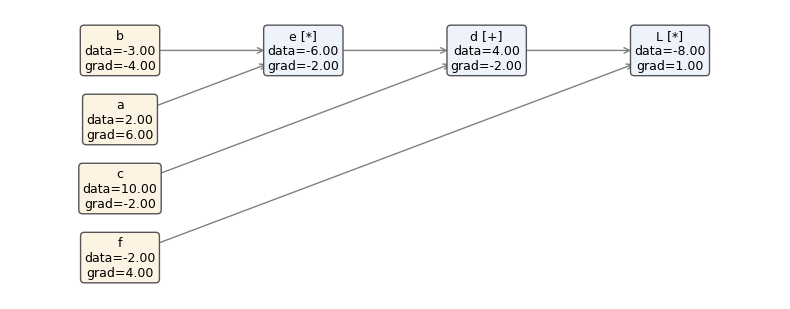

In [6]:
L.backward()
for v in (a, b, c, f, e, d):
    print(f'dL/d{v.label} = {v.grad}')
draw_graph(L, 'graph_backward.png')

### 5.1 Gradient accumulation (diamond graph) and numerical gradient check
When one variable is used several times its gradient contributions must be **summed** (`+=`).
We also compare backprop with a central finite difference
$\frac{\partial g}{\partial x} \approx \frac{g(x+h) - g(x-h)}{2h}$.

In [7]:
a = Value(3.0)
d = (a + a) * a          # = 2a^2 -> dd/da = 4a = 12
d.backward()
print('diamond graph: a.grad =', a.grad, '(expected 12.0)')

def g(x1, x2, x3):
    return ((x1 * x2 + x3).tanh() * (x1 ** 2).exp() - x2 / x3) ** 2

xs = [0.3, -1.2, 2.5]
vals = [Value(v) for v in xs]
g(*vals).backward()
h = 1e-6
print(f"{'input':6s} {'backprop':>14s} {'finite diff':>14s} {'abs error':>10s}")
for i, v in enumerate(vals):
    p = list(xs); p[i] += h
    m = list(xs); m[i] -= h
    num = (g(*map(Value, p)).data - g(*map(Value, m)).data) / (2 * h)
    print(f'x{i+1:<5d} {v.grad:14.8f} {num:14.8f} {abs(v.grad - num):10.2e}')

diamond graph: a.grad = 12.0 (expected 12.0)
input        backprop    finite diff  abs error
x1         1.75384622     1.75384622   1.14e-10
x2        -1.18082193    -1.18082193   2.62e-10
x3        -0.41096164    -0.41096164   5.22e-10


## 6. Neural Network Components
* `Neuron(nin)`: computes $\tanh(\sum_i w_i x_i + b)$ with $w_i, b \sim \mathcal{U}(-1, 1)$.
* `Layer(nin, nout)`: `nout` independent neurons on the same input; returns a list (or a single `Value` if `nout == 1`).
* `MLP(nin, nouts)`: a stack of layers with sizes `[nin] + nouts`.

In [8]:
random.seed(SEED)
n = Neuron(3)
print('Neuron(3):', len(n.parameters()), 'parameters ->', n([1.0, -2.0, 0.5]))

layer = Layer(3, 4)
print('Layer(3, 4):', len(layer.parameters()), 'parameters ->', layer([1.0, -2.0, 0.5]))

mlp = MLP(3, [4, 4, 1])
print('MLP(3, [4, 4, 1]):', len(mlp.parameters()), 'parameters ->', mlp([1.0, -2.0, 0.5]))

Neuron(3): 4 parameters -> Value(data=0.8854081310483286)
Layer(3, 4): 16 parameters -> [Value(data=-0.5835297348270263), Value(data=0.8964816334668579), Value(data=0.4601398886108109), Value(data=-0.9207228570859305)]
MLP(3, [4, 4, 1]): 41 parameters -> Value(data=0.3408718265567247)


## 7. Dataset — Two Moons
We use scikit-learn's `make_moons`: 2-D points from two interleaving half-circles with Gaussian noise.

**Why this dataset?**
* It is **not linearly separable**, so a hidden layer with a non-linearity is genuinely needed.
* It is 2-D, so the learned **decision boundary can be visualised** directly.
* It is small; our engine is scalar and pure Python, so a few hundred points keeps training to about a minute.

Labels are mapped from $\{0, 1\}$ to $\{-1, +1\}$ to match the range of the `tanh` output neuron.
The data is split 75 % / 25 % into train / test sets with a fixed seed.

train: (150, 2)  test: (50, 2)


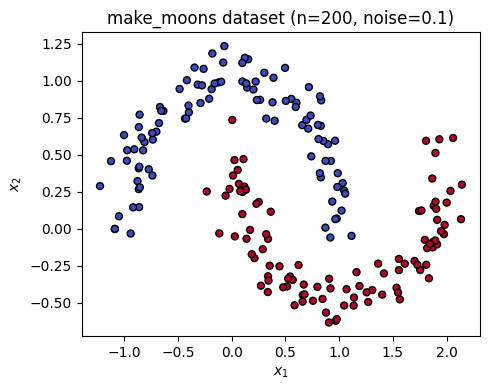

In [9]:
X, y01 = make_moons(n_samples=200, noise=0.1, random_state=SEED)
y = 2 * y01 - 1   # {0,1} -> {-1,+1}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print('train:', X_train.shape, ' test:', X_test.shape)

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=25)
plt.title('make_moons dataset (n=200, noise=0.1)'); plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'dataset.png'), dpi=150); plt.show()

## 8. Model Training
**Model:** `MLP(2, [16, 16, 1])` (2 → 16 → 16 → 1, all `tanh`), 337 parameters.

**Loss:** mean squared error between the `tanh` output $\hat y \in (-1, 1)$ and the target $y \in \{-1, +1\}$,
plus a small L2 penalty:
$$\mathcal{L} = \frac{1}{N}\sum_{i=1}^{N} (\hat y_i - y_i)^2 + \lambda \sum_j \theta_j^2, \qquad \lambda = 10^{-4}.$$

**Optimiser:** full-batch gradient descent, $\theta \leftarrow \theta - \eta\,\partial\mathcal{L}/\partial\theta$, with the
learning rate decayed linearly from 0.5 to 0.05.

Each step: forward pass → loss → `zero_grad()` → `backward()` → parameter update.

In [10]:
random.seed(SEED)
model = MLP(2, [16, 16, 1])
params = model.parameters()
print('number of parameters:', len(params))

def to_inputs(X):
    return [[float(v) for v in row] for row in X]

Xtr, Xte = to_inputs(X_train), to_inputs(X_test)
ytr, yte = [float(v) for v in y_train], [float(v) for v in y_test]

def loss_and_acc(Xs, ys, reg=1e-4):
    preds = [model(x) for x in Xs]
    data_loss = sum((p - t) ** 2 for p, t in zip(preds, ys)) * (1.0 / len(ys))
    reg_loss = reg * sum(p * p for p in params)
    acc = sum((p.data > 0) == (t > 0) for p, t in zip(preds, ys)) / len(ys)
    return data_loss + reg_loss, acc

STEPS = 100
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
t0 = time.time()
for k in range(STEPS):
    loss, acc = loss_and_acc(Xtr, ytr)      # forward + loss
    model.zero_grad()                        # clear old gradients
    loss.backward()                          # backprop through the whole graph
    lr = 0.5 - 0.45 * k / (STEPS - 1)
    for p in params:                         # gradient-descent update
        p.data -= lr * p.grad

    test_loss, test_acc = loss_and_acc(Xte, yte)
    history['train_loss'].append(loss.data); history['train_acc'].append(acc)
    history['test_loss'].append(test_loss.data); history['test_acc'].append(test_acc)
    if k % 10 == 0 or k == STEPS - 1:
        print(f'step {k:3d}  lr {lr:.3f}  train loss {loss.data:.4f}  train acc {acc:.3f}  '
              f'test loss {test_loss.data:.4f}  test acc {test_acc:.3f}')
print(f'training time: {time.time() - t0:.1f} s')

number of parameters: 337


step   0  lr 0.500  train loss 1.5459  train acc 0.513  test loss 0.6701  test acc 0.840


step  10  lr 0.455  train loss 0.3828  train acc 0.887  test loss 0.2103  test acc 0.960


step  20  lr 0.409  train loss 0.1807  train acc 0.947  test loss 0.1712  test acc 0.940


step  30  lr 0.364  train loss 0.6556  train acc 0.800  test loss 0.1646  test acc 0.960


step  40  lr 0.318  train loss 0.0588  train acc 0.987  test loss 0.0548  test acc 1.000


... (2 outputs left out)

step  70  lr 0.182  train loss 0.0392  train acc 0.993  test loss 0.0371  test acc 1.000


step  80  lr 0.136  train loss 0.0372  train acc 0.993  test loss 0.0356  test acc 1.000


step  90  lr 0.091  train loss 0.0360  train acc 0.993  test loss 0.0346  test acc 1.000


step  99  lr 0.050  train loss 0.0353  train acc 0.993  test loss 0.0341  test acc 1.000
training time: 156.7 s


In [11]:
final_train_loss, final_train_acc = loss_and_acc(Xtr, ytr)
final_test_loss, final_test_acc = loss_and_acc(Xte, yte)
print(f'FINAL  train loss {final_train_loss.data:.4f}  train acc {final_train_acc:.3f}')
print(f'FINAL  test  loss {final_test_loss.data:.4f}  test  acc {final_test_acc:.3f}')

FINAL  train loss 0.0353  train acc 0.993
FINAL  test  loss 0.0341  test  acc 1.000


## 9. Visualisation
### 9.1 Training curves

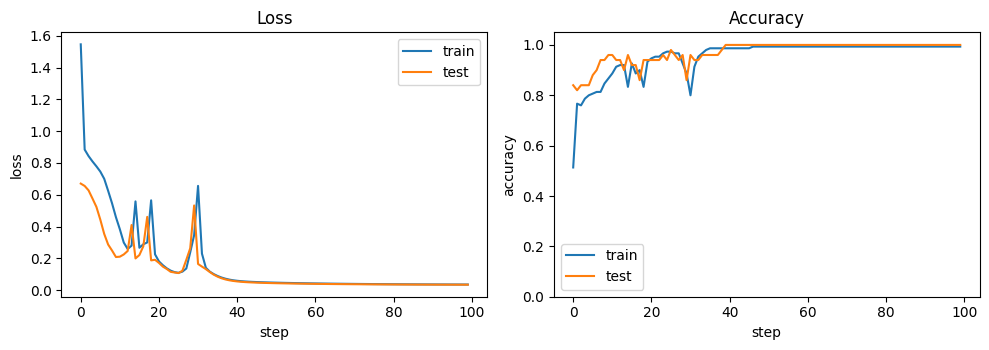

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(history['train_loss'], label='train'); axs[0].plot(history['test_loss'], label='test')
axs[0].set_xlabel('step'); axs[0].set_ylabel('loss'); axs[0].set_title('Loss'); axs[0].legend()
axs[1].plot(history['train_acc'], label='train'); axs[1].plot(history['test_acc'], label='test')
axs[1].set_xlabel('step'); axs[1].set_ylabel('accuracy'); axs[1].set_title('Accuracy'); axs[1].legend()
axs[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'training_curves.png'), dpi=150); plt.show()

### 9.2 Decision boundary
The trained network is evaluated (forward pass only, with our engine) on a grid covering the input space.
Training points are circles, test points are triangles.

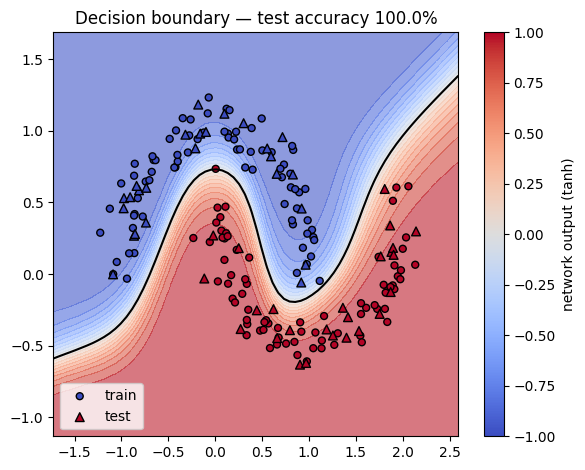

In [13]:
h = 0.06
xx, yy = np.meshgrid(np.arange(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, h),
                     np.arange(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, h))
Z = np.array([model([float(u), float(v)]).data for u, v in zip(xx.ravel(), yy.ravel())]).reshape(xx.shape)

plt.figure(figsize=(6, 4.8))
plt.contourf(xx, yy, Z, levels=np.linspace(-1, 1, 21), cmap='coolwarm', alpha=0.6)
plt.contour(xx, yy, Z, levels=[0], colors='k', linewidths=1.5)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=25, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolors='k', marker='^', s=40, label='test')
plt.colorbar(label='network output (tanh)')
plt.title(f'Decision boundary — test accuracy {final_test_acc:.1%}')
plt.legend(loc='lower left'); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'decision_boundary.png'), dpi=150); plt.show()

### 9.3 Actual vs. predicted (test set)

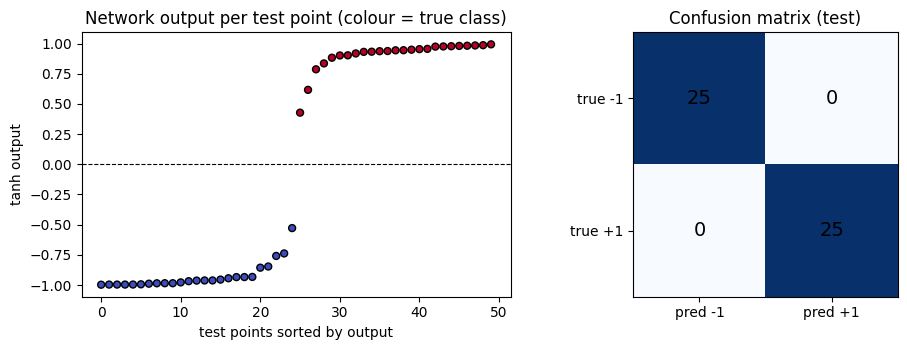

confusion matrix [rows=true -1,+1; cols=pred -1,+1]:
 [[25  0]
 [ 0 25]]


In [14]:
test_out = np.array([model(x).data for x in Xte])
test_pred = np.where(test_out > 0, 1, -1)
cm = np.array([[np.sum((y_test == t) & (test_pred == p)) for p in (-1, 1)] for t in (-1, 1)])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
order = np.argsort(test_out)
axs[0].scatter(range(len(order)), test_out[order], c=y_test[order], cmap='coolwarm', edgecolors='k', s=25)
axs[0].axhline(0, color='k', lw=0.8, ls='--')
axs[0].set_title('Network output per test point (colour = true class)')
axs[0].set_xlabel('test points sorted by output'); axs[0].set_ylabel('tanh output')
axs[1].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        axs[1].text(j, i, cm[i, j], ha='center', va='center', fontsize=14)
axs[1].set_xticks([0, 1], ['pred -1', 'pred +1']); axs[1].set_yticks([0, 1], ['true -1', 'true +1'])
axs[1].set_title('Confusion matrix (test)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'actual_vs_predicted.png'), dpi=150); plt.show()
print('confusion matrix [rows=true -1,+1; cols=pred -1,+1]:\n', cm)

## 10. Conclusion
* The `Value` class builds a computational graph through operator overloading and computes exact gradients
  with reverse-mode autodiff (topological sort + chain rule). Gradients match finite differences, and
  shared nodes (diamond graphs) accumulate gradients correctly.
* `Neuron`, `Layer` and `MLP` compose these scalars into a trainable network.
* Trained with plain gradient descent, entirely on our engine, the MLP learns a non-linear decision boundary
  on the two-moons dataset. The final metrics are printed above and reproduced on every run thanks to the fixed seeds.
* Limitation: one Python object per scalar makes the engine slow (≈ $10^5$ nodes per training step here),
  which is why real frameworks operate on tensors. The idea is the same, only vectorised.